# **Regression: Residential Property Price Prediction**

This notebook is a complete regression workflow built on `data/regression_data.csv` and the public helpers in `utils`.

**Scenario:** A real-estate analytics team wants a data-driven valuation model for residential properties. The model will support pricing discussions and help flag listings that look over- or under-priced.

**Target:** `price`.

**Primary metrics:** RMSE and MAE in dollars, with R² as a relative fit measure. RMSE penalizes large valuation errors; MAE is easier to explain to business stakeholders.

## **STAGE 0: BUSINESS UNDERSTANDING**

### Problem statement
Manual valuations are slow and inconsistent. The team wants a repeatable baseline that uses property characteristics, location, and condition to estimate price.

### Goals
- Build a leakage-safe regression workflow.
- Compare linear and tree-based baselines.
- Tune the strongest candidate on validation data.
- Estimate the dollar error on a held-out test set.
- Explain which features drive predictions.

### Success criteria
- Test R² meaningfully above zero.
- MAE and RMSE reported in dollars, not only as unitless scores.
- Preprocessing is fitted on training data only.
- The final test set is untouched until the last evaluation.

## **STAGE 1: PROJECT SETUP**

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

from utils import (
    calculate_correlation_tabular,
    calculate_feature_importance,
    check_data_information,
    compare_cv_metrics_regression,
    describe_categorical_combined,
    describe_numerical_combined,
    eval_regression,
    feature_encoding,
    feature_scaling,
    filter_outliers,
    get_model_pipeline,
    handle_missing_values,
    plot_correlation_heatmap,
    plot_dynamic_countplot,
    plot_dynamic_hisplots_kdeplots,
    tune_single_model_regression,
)

warnings.filterwarnings("ignore")
sns.set_style("darkgrid")
pd.set_option("display.max_columns", None)

NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR
DATA_PATH = PROJECT_ROOT / "data" / "regression_data.csv"
print(f"Project root: {PROJECT_ROOT}")
print(f"Data path:    {DATA_PATH}")

Project root: e:\Data Science Utils
Data path:    e:\Data Science Utils\data\regression_data.csv


## **STAGE 2: LOAD AND INSPECT**

In [2]:
df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()

print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
display(df.head())

Rows: 1,050 | Columns: 22


,property_id,sqft_living,sqft_lot,bedrooms,bathrooms,floors,year_built,year_renovated,condition,grade,waterfront,view,city,zipcode,latitude,longitude,distance_to_downtown,school_rating,crime_rate,has_garage,sqft_basement,price
0,PROP_00352,2074.974764,12666.739468,3,2.5,2.0,2023.0,0.0,3,6.0,0,0,Other,98157,47.312479,-121.844119,5.396556,9.2,0.611506,Yes,NaN,600130.395571
1,PROP_00689,1207.077982,7376.062644,2,2.0,2.0,1968.0,1996.0,2,7.0,Yes,0,Seattle,98100,47.733808,-122.010631,23.112477,NaN,5.565608,TRUE,0.0,712611.769228
2,PROP_00485,3314.232769,2414.299701,2,4.0,3.0,1920.0,0.0,3,6.0,1,2,Other,98162,47.319195,-122.238151,8.284677,3.5,8.725351,0,636.1059800711031,732686.449934
3,PROP_00388,NaN,NaN,2,2.0,2.0,2007.0,2020.0,3,8.0,0,3,Seattle,98196,47.111920,-121.573947,3.453021,8.6,3.260463,Yes,0.0,706438.425496
4,PROP_00031,1186.961252,5917.575635,1,2.0,2.0,1996.0,0.0,1,9.0,0,0,Seattle,98045,47.283425,-122.111706,1.565135,6.5,0.751626,1,0.0,531928.517099


In [3]:
info_df = check_data_information(df, df.columns.tolist())
display(info_df)

,Feature,Data Type,Null Values,Null Percentage,Zero Values,Zero Percentage,Negative Values,Negative Percentage,Empty Strings,Numeric in Object,Duplicated Values,Unique Values,Cardinality Ratio,Unique Sample
0,property_id,object,0,0.00,0,0.00,0,0.00,0,0,50,1000,0.9524,"PROP_00352, PROP_00689, PROP_00485, PROP_00388..."
1,sqft_living,float64,88,8.38,0,0.00,7,0.67,0,0,50,914,0.8705,"2074.9747640549976, 1207.0779821460708, 3314.2..."
2,sqft_lot,float64,89,8.48,0,0.00,10,0.95,0,0,50,914,0.8705,"12666.73946770685, 7376.06264433528, 2414.2997..."
3,bedrooms,int64,0,0.00,2,0.19,0,0.00,0,0,50,13,0.0124,"3, 2, 1, 7, 6"
4,bathrooms,float64,0,0.00,0,0.00,0,0.00,0,0,50,9,0.0086,"2.5, 2.0, 4.0, 3.0, 1.5"
5,floors,float64,0,0.00,0,0.00,0,0.00,0,0,50,5,0.0048,"2.0, 3.0, 1.0, 2.5, 1.5"
6,year_built,float64,86,8.19,0,0.00,0,0.00,0,0,50,104,0.0990,"2023.0, 1968.0, 1920.0, 2007.0, 1996.0"
7,year_renovated,float64,96,9.14,662,63.05,0,0.00,0,0,50,43,0.0410,"0.0, 1996.0, 2020.0, 1994.0, nan"
8,condition,int64,0,0.00,0,0.00,0,0.00,0,0,50,5,0.0048,"3, 2, 1, 4, 5"
9,grade,float64,91,8.67,0,0.00,0,0.00,0,0,50,13,0.0124,"6.0, 7.0, 8.0, 9.0, 11.0"


### Data-quality issues visible in the raw data
- `sqft_living`, `sqft_lot`, `sqft_basement`, and `price` contain missing values.
- `sqft_living` and `sqft_lot` contain negative values, which are physically impossible.
- `sqft_basement` is stored as text with blank strings and placeholders such as `None`, `TBA`, and `Check Plan`.
- `waterfront` and `has_garage` mix numeric and text representations.
- `city` has inconsistent casing and whitespace.
- `zipcode` is numeric but is a high-cardinality location identifier, not a continuous quantity.

The next cell fixes these issues without using target statistics.

In [4]:
# Drop the identifier; it carries no generalizable signal.
df = df.drop(columns=["property_id"])

# Normalize location text.
df["city"] = (
    df["city"]
    .astype(str)
    .str.strip()
    .str.title()
    .replace({"": "Unknown", "Nan": "Unknown"})
)
df["zipcode"] = df["zipcode"].astype(str).str.strip()

# Normalize binary-looking columns to Yes/No.
yes_no_map = {
    "1": "Yes", "0": "No",
    "yes": "Yes", "no": "No",
    "true": "Yes", "false": "No",
}
df["waterfront"] = (
    df["waterfront"].astype(str).str.strip().str.lower()
    .map(yes_no_map).fillna("No")
)
df["has_garage"] = (
    df["has_garage"].astype(str).str.strip().str.lower()
    .map(yes_no_map).fillna("No")
)

# Convert basement text to numeric and treat placeholders as missing.
df["sqft_basement"] = (
    df["sqft_basement"]
    .astype(str)
    .str.strip()
    .replace({"": np.nan, "None": np.nan, "TBA": np.nan, "Check Plan": np.nan, "nan": np.nan})
)
df["sqft_basement"] = pd.to_numeric(df["sqft_basement"], errors="coerce")

# Negative square footage and price are data-entry errors.
for col in ["sqft_living", "sqft_lot", "sqft_basement", "price"]:
    df.loc[df[col] < 0, col] = np.nan

# The target cannot be imputed for supervised learning.
df = df.dropna(subset=["price"]).copy()

# Derived features that are more interpretable than raw years.
df["house_age"] = 2024 - df["year_built"]
df["was_renovated"] = np.where(df["year_renovated"] > 0, "Yes", "No")

df = df.reset_index(drop=True)
print(f"Shape after basic cleaning: {df.shape}")

Shape after basic cleaning: (965, 23)


In [5]:
print(df["price"].describe().to_frame("price").T)
missing = df.isna().sum().sort_values(ascending=False)
display(missing[missing > 0].to_frame("missing_count"))

       count          mean           std      min            25%  \
price  965.0  789960.86661  1.061590e+06  50000.0  499328.173392   

                 50%            75%           max  
price  597665.603277  731377.495889  9.848359e+06  


,missing_count
sqft_basement,144
sqft_lot,96
year_renovated,89
sqft_living,86
grade,83
school_rating,83
crime_rate,81
house_age,74
year_built,74


## **STAGE 3: EXPLORATORY DATA ANALYSIS**

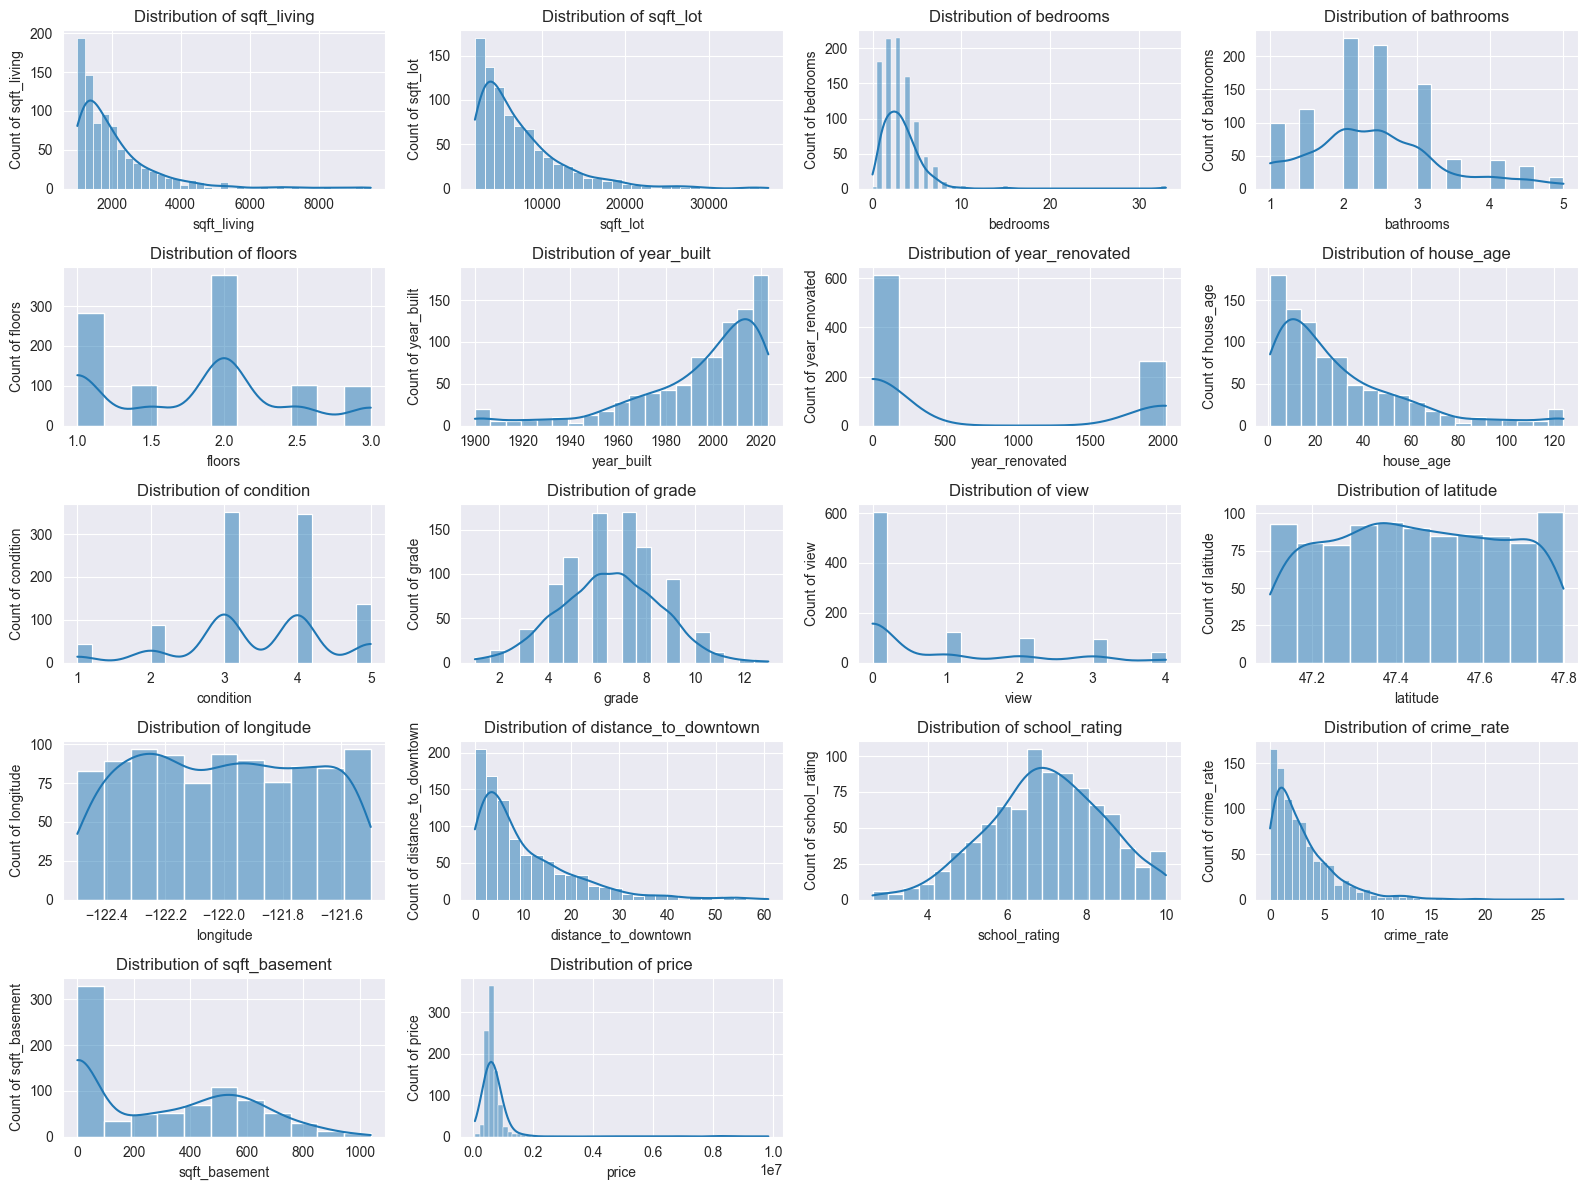

,Feature,overall_count,overall_mean,overall_std,overall_min,overall_25%,overall_50%,overall_75%,overall_max,overall_range,overall_IQR,overall_CV,overall_skewness,overall_kurtosis
0,sqft_living,879.0,2104.123159,1.295951e+03,1004.642784,1281.903441,1726.291119,2407.903300,9.512727e+03,8.508084e+03,1125.999859,61.591020,2.691816,9.379873
1,sqft_lot,869.0,7310.926266,5.277489e+03,2011.210444,3621.765914,5746.018190,9300.243354,3.713835e+04,3.512714e+04,5678.477441,72.186331,1.979909,5.312873
2,bedrooms,965.0,3.280829,2.667014e+00,0.000000,2.000000,3.000000,4.000000,3.300000e+01,3.300000e+01,2.000000,81.290847,6.166706,62.805934
3,bathrooms,965.0,2.416062,9.263327e-01,1.000000,2.000000,2.500000,3.000000,5.000000e+00,4.000000e+00,1.000000,38.340601,0.638977,0.235943
4,floors,965.0,1.811399,6.438946e-01,1.000000,1.000000,2.000000,2.000000,3.000000e+00,2.000000e+00,1.000000,35.546811,0.193849,-0.904684
5,year_built,891.0,1994.409652,2.797060e+01,1900.000000,1983.000000,2003.000000,2015.000000,2.023000e+03,1.230000e+02,32.000000,1.402450,-1.529310,2.123526
6,year_renovated,876.0,600.334475,9.195757e+02,0.000000,0.000000,0.000000,1992.250000,2.023000e+03,2.023000e+03,1992.250000,153.177219,0.877812,-1.229171
7,house_age,891.0,29.590348,2.797060e+01,1.000000,9.000000,21.000000,41.000000,1.240000e+02,1.230000e+02,32.000000,94.526094,1.529310,2.123526
8,condition,965.0,3.462176,9.895037e-01,1.000000,3.000000,4.000000,4.000000,5.000000e+00,4.000000e+00,1.000000,28.580399,-0.428473,0.015262
9,grade,882.0,6.513605,2.020423e+00,1.000000,5.000000,7.000000,8.000000,1.300000e+01,1.200000e+01,3.000000,31.018499,-0.017322,-0.083333


In [6]:
target = "price"

numeric_features = [
    "sqft_living", "sqft_lot", "bedrooms", "bathrooms", "floors",
    "year_built", "year_renovated", "house_age", "condition", "grade",
    "view", "latitude", "longitude", "distance_to_downtown",
    "school_rating", "crime_rate", "sqft_basement",
]
categorical_features = ["waterfront", "city", "zipcode", "has_garage", "was_renovated"]

plot_dynamic_hisplots_kdeplots(df, numeric_features + [target], ncols=4, figsize=(16, 12))
display(describe_numerical_combined(df, numeric_features + [target]))

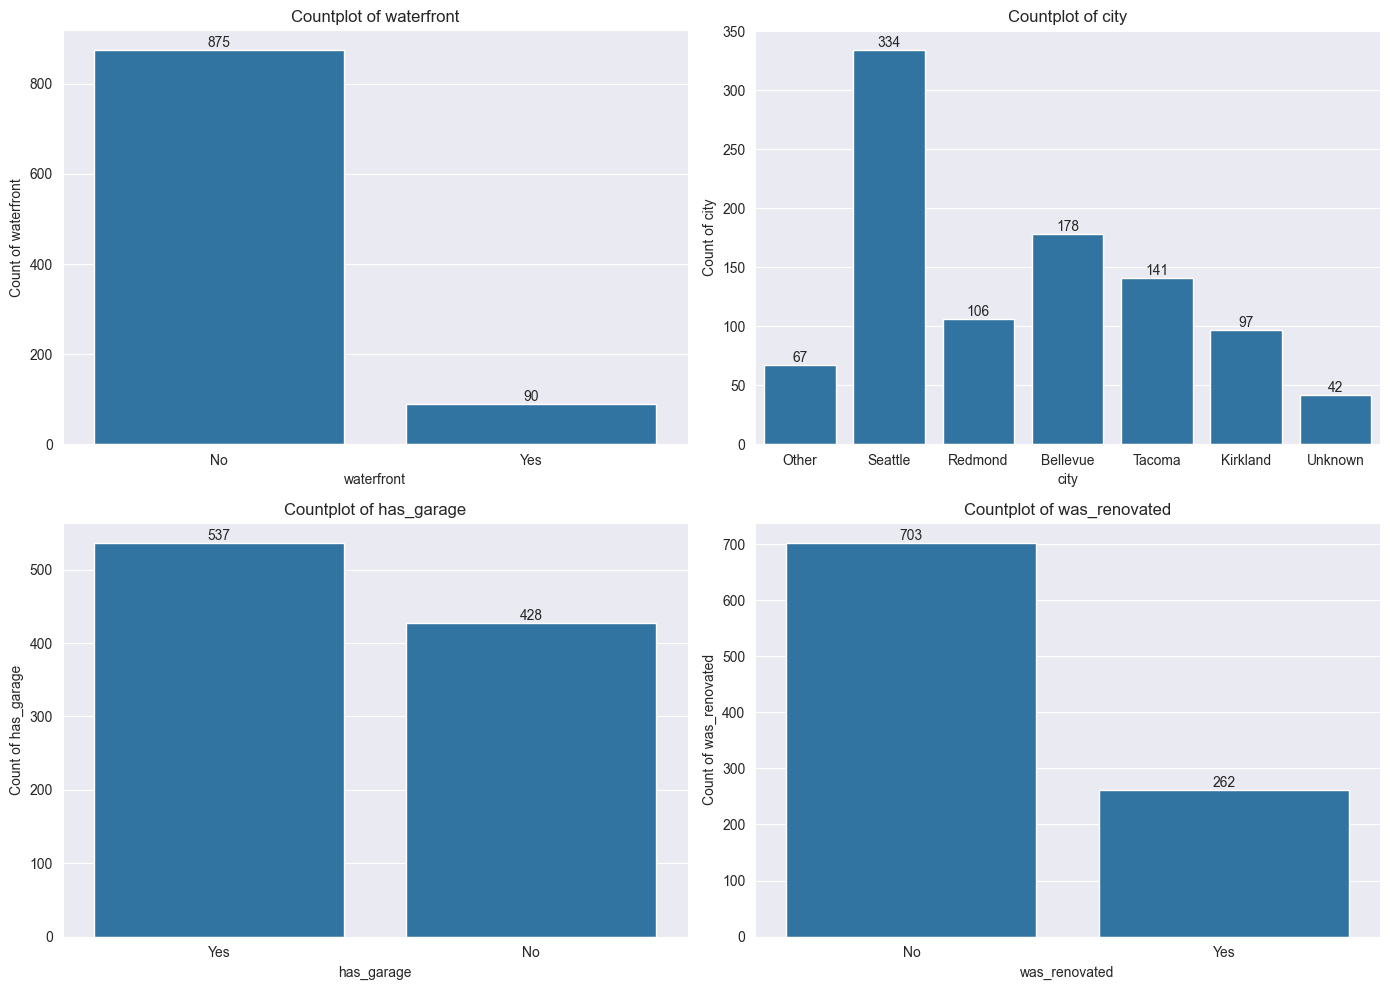

,Feature,overall_count,overall_unique,overall_top,overall_freq,overall_bottom,overall_freq_bottom,overall_top_percentage,overall_bottom_percentage,overall_n_categories
0,waterfront,965,2,No,875,Yes,90,90.67,9.33,2
1,city,965,7,Seattle,334,Unknown,42,34.61,4.35,7
2,zipcode,965,196,98007,13,98001,1,1.35,0.10,196
3,has_garage,965,2,Yes,537,No,428,55.65,44.35,2
4,was_renovated,965,2,No,703,Yes,262,72.85,27.15,2


In [7]:
countplot_cols = ["waterfront", "city", "has_garage", "was_renovated"]
plot_dynamic_countplot(df, countplot_cols, ncols=2, figsize=(14, 10))
display(describe_categorical_combined(df, categorical_features))

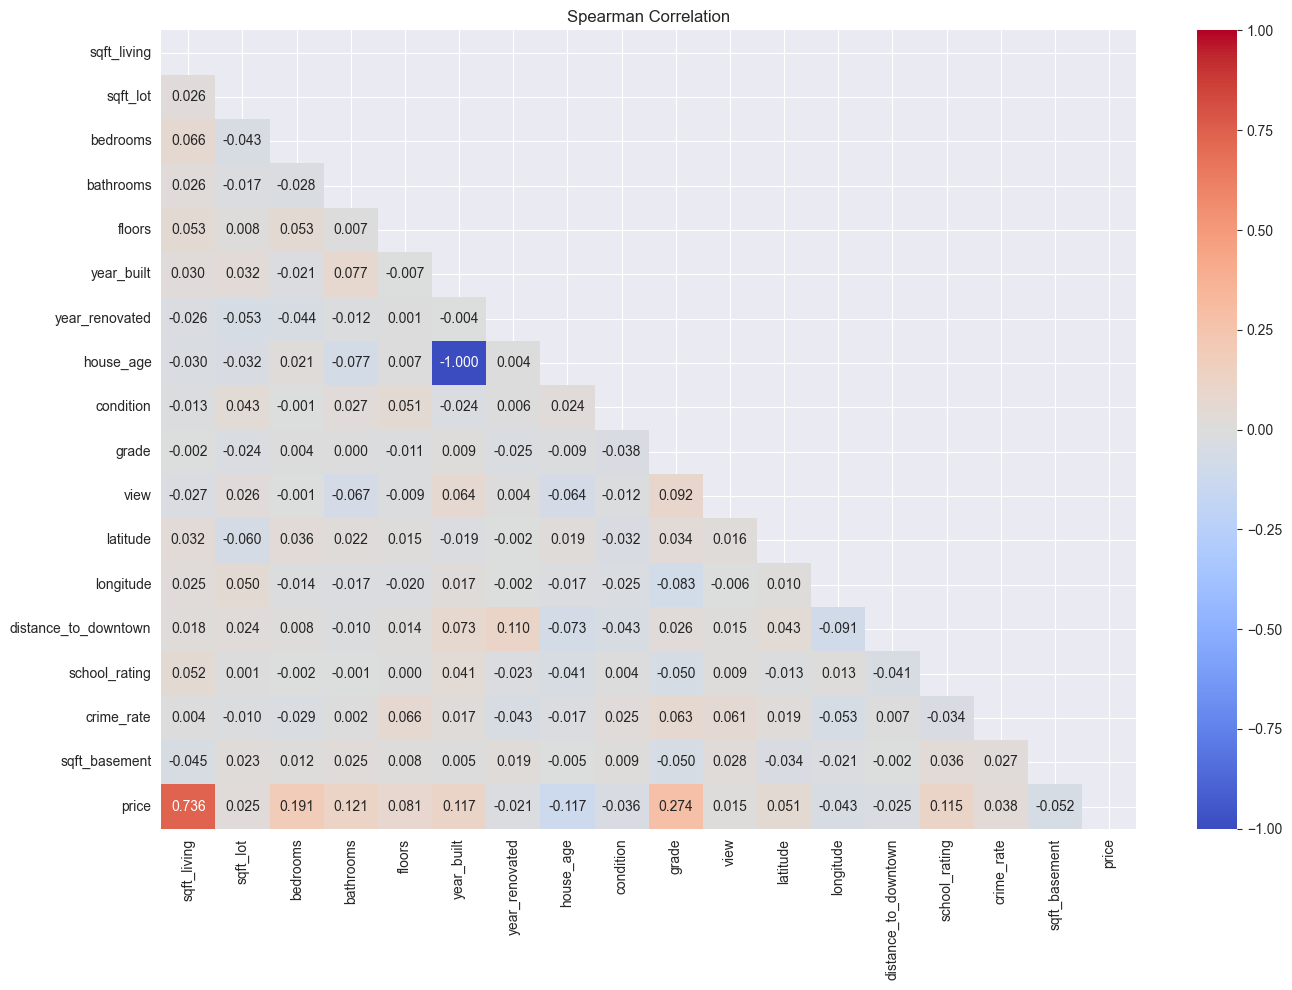

In [8]:
plot_correlation_heatmap(
    df,
    numeric_features + [target],
    corr_method="spearman",
    figsize=(14, 10),
)

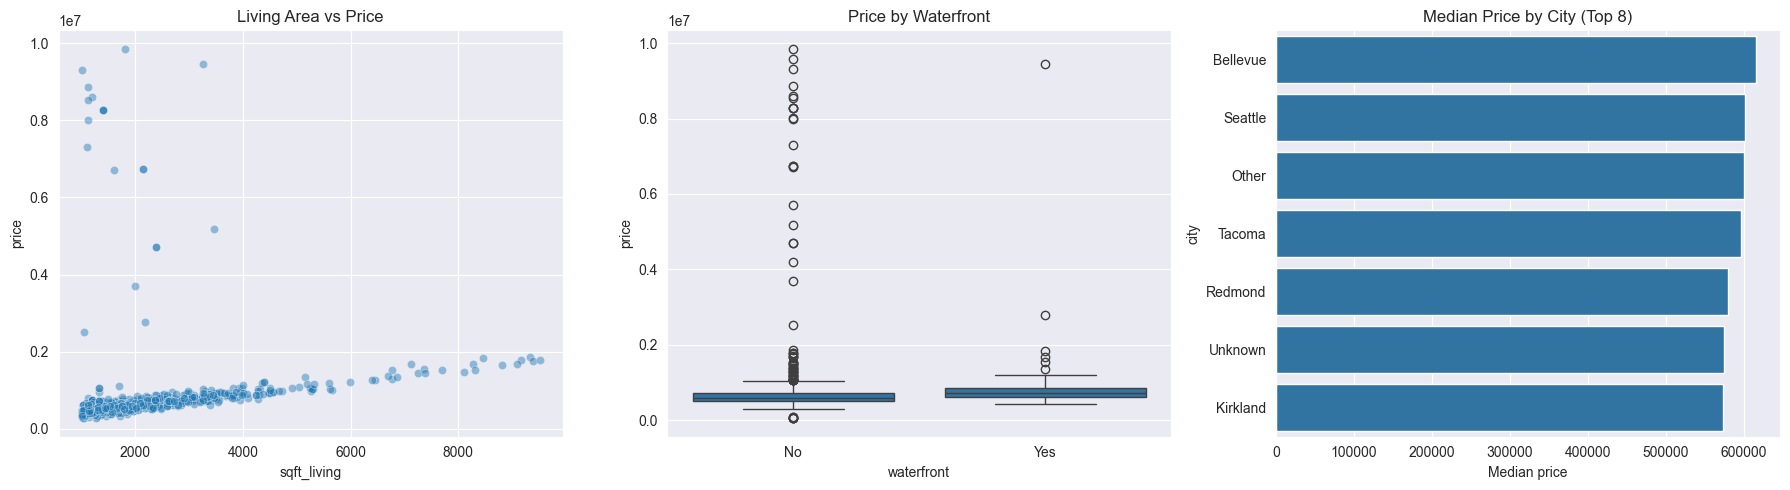

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(data=df, x="sqft_living", y=target, alpha=0.45, ax=axes[0])
axes[0].set_title("Living Area vs Price")

sns.boxplot(data=df, x="waterfront", y=target, ax=axes[1])
axes[1].set_title("Price by Waterfront")

city_median = df.groupby("city")[target].median().sort_values(ascending=False).head(8)
sns.barplot(x=city_median.values, y=city_median.index, ax=axes[2])
axes[2].set_title("Median Price by City (Top 8)")
axes[2].set_xlabel("Median price")

plt.tight_layout()
plt.show()

### EDA takeaways
- Price is right-skewed with a small number of luxury outliers.
- Living area, grade, and location are expected to be strong predictors.
- Waterfront is rare but likely carries a large premium.
- `year_built` and `house_age` are perfectly redundant; feature selection should remove one.
- `zipcode` has too many categories for one-hot encoding in a small dataset, so it is frequency-encoded later.

## **STAGE 4: TRAIN / VALIDATION / TEST SPLIT**

The split happens before imputation, outlier handling, encoding, selection, and scaling. The test set is held back for the final evaluation only.

In [10]:
X_raw = df.drop(columns=[target])
y_raw = df[target]

X_train_raw, X_temp_raw, y_train_raw, y_temp_raw = train_test_split(
    X_raw, y_raw, test_size=0.25, random_state=42
)
X_val_raw, X_test_raw, y_val_raw, y_test_raw = train_test_split(
    X_temp_raw, y_temp_raw, test_size=0.2, random_state=42
)

total = len(X_raw)
print(f"Total rows:   {total:,}")
print(f"Train:        {len(X_train_raw):,} ({len(X_train_raw)/total*100:.1f}%)")
print(f"Validation:   {len(X_val_raw):,} ({len(X_val_raw)/total*100:.1f}%)")
print(f"Test:         {len(X_test_raw):,} ({len(X_test_raw)/total*100:.1f}%)")

Total rows:   965
Train:        723 (74.9%)
Validation:   193 (20.0%)
Test:         49 (5.1%)


## **STAGE 5: PREPROCESSING FITTED ON TRAINING DATA**

### Missing-value imputation
Numeric columns use the training median. Categorical columns use the training mode. Validation and test data receive the training statistics, not their own.

In [11]:
numeric_missing = [
    col for col in X_train_raw.columns
    if X_train_raw[col].isna().any() and pd.api.types.is_numeric_dtype(X_train_raw[col])
]
categorical_missing = [
    col for col in X_train_raw.columns
    if X_train_raw[col].isna().any() and col not in numeric_missing
]

train_medians = X_train_raw[numeric_missing].median()
train_modes = {}
for col in categorical_missing:
    mode = X_train_raw[col].mode()
    train_modes[col] = mode.iloc[0] if not mode.empty else "Unknown"

X_train_imp, _ = handle_missing_values(
    X_train_raw.copy(),
    columns=numeric_missing,
    strategy="median",
)
for col in categorical_missing:
    X_train_imp[col] = X_train_imp[col].fillna(train_modes[col])

def apply_training_imputation(X):
    X = X.copy()
    if numeric_missing:
        X[numeric_missing] = X[numeric_missing].fillna(train_medians)
    for col in categorical_missing:
        X[col] = X[col].fillna(train_modes[col])
    return X

X_val_imp = apply_training_imputation(X_val_raw)
X_test_imp = apply_training_imputation(X_test_raw)

print(f"Numeric columns imputed: {len(numeric_missing)}")
print(f"Categorical columns imputed: {len(categorical_missing)}")
print(f"Remaining train missing values: {X_train_imp.isna().sum().sum()}")

Numeric columns imputed: 9
Categorical columns imputed: 0
Remaining train missing values: 0


### Outlier handling
IQR limits are learned from the training features only. Training rows outside the limits are removed. The same limits are applied to validation rows. The test set is not filtered, because it must represent unseen production data.

In [12]:
outlier_cols = [col for col in numeric_features if col in X_train_imp.columns]

outlier_summary = filter_outliers(
    pd.concat([X_train_imp, y_train_raw], axis=1),
    columns=outlier_cols,
    method="iqr",
    threshold=1.5,
    detect_only=True,
    verbose=False,
)
display(outlier_summary)

train_mask = filter_outliers(
    X_train_imp,
    columns=outlier_cols,
    method="iqr",
    threshold=1.5,
    return_mask=True,
)[1]
X_train_clean = X_train_imp[train_mask].copy()
y_train_clean = y_train_raw[train_mask].copy()

def apply_training_limits(X, limits_df, columns):
    """Apply training-derived IQR limits to a validation/test feature frame."""
    mask = np.ones(len(X), dtype=bool)
    for _, row in limits_df.iterrows():
        col = row["Column Name"]
        if col in columns and col in X.columns:
            mask &= X[col].between(row["Lower Limit"], row["Upper Limit"]).to_numpy()
    return X[mask].copy(), mask

X_val_clean, val_mask = apply_training_limits(X_val_imp, outlier_summary, outlier_cols)
y_val_clean = y_val_raw[val_mask].copy()

print(f"Train after outlier removal: {len(X_train_clean):,} rows")
print(f"Validation after limits:     {len(X_val_clean):,} rows")
print(f"Test kept untouched:         {len(X_test_imp):,} rows")

,Column Name,Outlier Exist,Lower Limit,Upper Limit,Outlier Data,Non-Outlier Data,Outlier Percentage (%)
0,sqft_living,True,-212.412481,3818.278443,53,670,7.33
1,sqft_lot,True,-3615.760763,16037.516632,44,679,6.09
2,bedrooms,True,-1.000000,7.000000,15,708,2.07
3,bathrooms,True,0.500000,4.500000,15,708,2.07
4,floors,False,-0.500000,3.500000,0,723,0.00
5,year_built,True,1944.000000,2056.000000,43,680,5.95
6,year_renovated,False,-2977.500000,4962.500000,0,723,0.00
7,house_age,True,-32.000000,80.000000,43,680,5.95
8,condition,True,1.500000,5.500000,32,691,4.43
9,grade,True,0.500000,12.500000,1,722,0.14


Train after outlier removal: 420 rows
Validation after limits:     103 rows
Test kept untouched:         49 rows


### Feature encoding
- `city` is one-hot encoded (low cardinality).
- `waterfront`, `has_garage`, and `was_renovated` are binary-encoded.
- `zipcode` is frequency-encoded to avoid an explosion of one-hot columns.
- Encoders are fitted on training data and reused for validation and test.

In [13]:
nominal_cols = ["city"]
binary_cols = ["waterfront", "has_garage", "was_renovated"]
frequency_cols = ["zipcode"]

X_train_encoded, encoders = feature_encoding(
    data=X_train_clean.copy(),
    nominal_columns=nominal_cols,
    binary_columns=binary_cols,
    frequency_columns=frequency_cols,
    handle_unknown="ignore",
)
X_val_encoded, _ = feature_encoding(
    data=X_val_clean.copy(),
    nominal_columns=nominal_cols,
    binary_columns=binary_cols,
    frequency_columns=frequency_cols,
    encoders=encoders,
    handle_unknown="ignore",
)
X_test_encoded, _ = feature_encoding(
    data=X_test_imp.copy(),
    nominal_columns=nominal_cols,
    binary_columns=binary_cols,
    frequency_columns=frequency_cols,
    encoders=encoders,
    handle_unknown="ignore",
)

print(f"Encoded training shape: {X_train_encoded.shape}")
print(X_train_encoded.columns.tolist())

Encoded training shape: (420, 27)
['city_Kirkland', 'city_Other', 'city_Redmond', 'city_Seattle', 'city_Tacoma', 'city_Unknown', 'sqft_living', 'sqft_lot', 'bedrooms', 'bathrooms', 'floors', 'year_built', 'year_renovated', 'condition', 'grade', 'waterfront', 'view', 'zipcode', 'latitude', 'longitude', 'distance_to_downtown', 'school_rating', 'crime_rate', 'has_garage', 'sqft_basement', 'house_age', 'was_renovated']


## **STAGE 6: FEATURE SELECTION**

Correlation and univariate importance are computed on training data only. Highly correlated candidates are pruned so the linear models do not receive near-duplicate columns.

In [14]:
df_train_encoded = pd.concat(
    [X_train_encoded.reset_index(drop=True), y_train_clean.reset_index(drop=True)],
    axis=1,
)
feature_feature_df, feature_target_df = calculate_correlation_tabular(
    df_train_encoded,
    target_col=target,
    method="spearman",
    corr_type="both",
)

Correlation Between Features:


,A,B,Corr Value,Corr Type
0,house_age,year_built,1.000000,Negative
1,city_Seattle,city_Tacoma,0.323498,Negative
2,city_Kirkland,city_Seattle,0.271069,Negative
3,city_Redmond,city_Seattle,0.267615,Negative
4,city_Seattle,city_Unknown,0.195077,Negative
5,city_Other,city_Seattle,0.162749,Negative
6,city_Kirkland,city_Tacoma,0.139655,Negative
7,city_Redmond,city_Tacoma,0.137876,Negative
8,distance_to_downtown,year_built,0.123647,Positive
9,distance_to_downtown,house_age,0.123647,Negative



Correlation of Features to Target:


,Feature,Corr Value,Corr Type
0,sqft_living,0.654255,Positive
1,grade,0.357489,Positive
2,bedrooms,0.201788,Positive
3,year_built,0.135969,Positive
4,house_age,0.135969,Negative
5,bathrooms,0.132455,Positive
6,school_rating,0.113296,Positive
7,latitude,0.108470,Positive
8,city_Other,0.083455,Negative
9,condition,0.077912,Negative


In [15]:
importance_f = calculate_feature_importance(
    X=X_train_encoded,
    y=y_train_clean.reset_index(drop=True),
    task="regression",
    method="f_regression",
    k="all",
)
importance_mi = calculate_feature_importance(
    X=X_train_encoded,
    y=y_train_clean.reset_index(drop=True),
    task="regression",
    method="mutual_info",
    k="all",
)

print("Top F-regression features")
display(importance_f.head(15).reset_index(drop=True))
print("Top mutual-information features")
display(importance_mi.head(15).reset_index(drop=True))

Top F-regression features


,Feature,Score,P_Values
0,bedrooms,9.970574,0.001706
1,city_Unknown,7.139855,0.007834
2,latitude,5.953483,0.015103
3,grade,5.434661,0.020216
4,sqft_lot,4.294819,0.038841
5,distance_to_downtown,3.001418,0.083929
6,was_renovated,2.027548,0.155216
7,year_renovated,2.020081,0.155976
8,has_garage,1.585876,0.208619
9,view,1.523550,0.217777


Top mutual-information features


,Feature,Score,P_Values
0,sqft_living,0.422963,None
1,grade,0.108044,None
2,condition,0.092641,None
3,year_built,0.088866,None
4,house_age,0.080050,None
5,bedrooms,0.069070,None
6,longitude,0.063933,None
7,school_rating,0.062653,None
8,sqft_lot,0.058150,None
9,sqft_basement,0.049976,None


In [16]:
candidate_features = importance_mi.head(20)["Feature"].tolist()
corr_matrix = X_train_encoded[candidate_features].corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [col for col in upper.columns if (upper[col] > 0.9).any()]

selected_cols = [col for col in candidate_features if col not in to_drop]
if len(selected_cols) < 8:
    selected_cols = importance_mi.head(12)["Feature"].tolist()

X_train_selected = X_train_encoded[selected_cols].copy()
X_val_selected = X_val_encoded[selected_cols].copy()
X_test_selected = X_test_encoded[selected_cols].copy()

print(f"Selected {len(selected_cols)} features")
print(selected_cols)
print(f"Train shape: {X_train_selected.shape}")
print(f"Validation shape: {X_val_selected.shape}")
print(f"Test shape: {X_test_selected.shape}")

Selected 18 features
['sqft_living', 'grade', 'condition', 'year_built', 'bedrooms', 'longitude', 'school_rating', 'sqft_lot', 'sqft_basement', 'bathrooms', 'waterfront', 'city_Tacoma', 'latitude', 'zipcode', 'city_Seattle', 'was_renovated', 'floors', 'has_garage']
Train shape: (420, 18)
Validation shape: (103, 18)
Test shape: (49, 18)


### Feature scaling
Binary-like columns use min-max scaling; continuous columns use standardization. The scalers are fitted on training data and reused for validation and test.

In [17]:
binary_like = [col for col in selected_cols if X_train_encoded[col].nunique() <= 2]
continuous_cols = [col for col in selected_cols if col not in binary_like]

scaling_config = {}
if continuous_cols:
    scaling_config["standard"] = {"columns": continuous_cols}
if binary_like:
    scaling_config["minmax"] = {"columns": binary_like}

X_train_scaled, scalers = feature_scaling(
    X_train_selected,
    scaling_config=scaling_config,
)
X_val_scaled, _ = feature_scaling(
    X_val_selected,
    scaling_config=scaling_config,
    scaler=scalers,
)
X_test_scaled, _ = feature_scaling(
    X_test_selected,
    scaling_config=scaling_config,
    scaler=scalers,
)

print(f"Continuous columns scaled with standard: {len(continuous_cols)}")
print(f"Binary-like columns scaled with minmax: {len(binary_like)}")
print(f"Train scaled shape: {X_train_scaled.shape}")

Continuous columns scaled with standard: 13
Binary-like columns scaled with minmax: 5
Train scaled shape: (420, 18)


## **STAGE 7: BASELINE REGRESSION MODELS**

All models are trained on the scaled training set and evaluated on the validation set. Cross-validated metrics are computed on the training set with repeated K-fold.

In [18]:
model_keys = [
    "linearregression", "ridge", "lasso", "knn",
    "decisiontree", "randomforest", "xgboost",
]
display_names = {
    "linearregression": "Linear Regression",
    "ridge": "Ridge",
    "lasso": "Lasso",
    "knn": "K-Nearest Neighbors",
    "decisiontree": "Decision Tree",
    "randomforest": "Random Forest",
    "xgboost": "XGBoost",
}

baseline_models = {
    display_names[key]: get_model_pipeline(key, random_state=42)
    for key in model_keys
}

for name, model in baseline_models.items():
    model.fit(X_train_scaled, y_train_clean)
    print(f"Trained {name}")

Trained Linear Regression
Trained Ridge
Trained Lasso
Trained K-Nearest Neighbors
Trained Decision Tree
Trained Random Forest
Trained XGBoost


In [19]:
baseline_metrics = {}
for name, model in baseline_models.items():
    baseline_metrics[name] = eval_regression(
        model=model,
        X_train=X_train_scaled,
        y_train=y_train_clean,
        X_test=X_val_scaled,
        y_test=y_val_clean,
        plot_predicted_vs_actual=False,
        plot_residuals=False,
        plot_residuals_dist=False,
        n_splits=5,
        n_repeats=2,
        display=False,
        show_plots=False,
    )
    print(f"Evaluated {name}")

Evaluated Linear Regression
Evaluated Ridge
Evaluated Lasso
Evaluated K-Nearest Neighbors
Evaluated Decision Tree
Evaluated Random Forest
Evaluated XGBoost


In [20]:
comparison = compare_cv_metrics_regression(baseline_metrics, as_numeric=True)
comparison = comparison.sort_values("R2", ascending=False).reset_index(drop=True)
display(comparison)

,Model,MAE,MSE,RMSE,MAPE,R2
0,Ridge,374308.135417,9.040533e+11,8.891728e+05,0.539327,-0.998755
1,Lasso,375463.670272,9.046507e+11,8.897136e+05,0.541605,-1.010607
2,Linear Regression,375466.795936,9.046519e+11,8.897147e+05,0.541612,-1.010634
3,Random Forest,308738.637337,8.353475e+11,8.505683e+05,0.450954,-1.954649
4,K-Nearest Neighbors,325232.614549,9.692070e+11,9.313208e+05,0.455674,-2.044254
5,XGBoost,300049.707159,1.054601e+12,9.436460e+05,0.459961,-2.954267
6,Decision Tree,316633.515781,1.468276e+12,1.180409e+06,0.470283,-12.320372


In [21]:
best_model_name = comparison.iloc[0]["Model"]
best_model_key = {name: key for key, name in display_names.items()}[best_model_name]
print(f"Best baseline by cross-validated R²: {best_model_name}")
print(f"Model key: {best_model_key}")

Best baseline by cross-validated R²: Ridge
Model key: ridge


## **STAGE 8: HYPERPARAMETER TUNING**

The best baseline is tuned with randomized search on the training set. The validation set is used only to report the holdout score, not to fit the search.

In [22]:
tuned_search, fit_time = tune_single_model_regression(
    model_name=best_model_key,
    X_train=X_train_scaled,
    y_train=y_train_clean,
    X_test=X_val_scaled,
    y_test=y_val_clean,
    scoring="r2",
    search_method="random",
    n_iter=20,
    n_splits=3,
    n_repeats=1,
    random_state=42,
    display=False,
    plot_validation_curves=False,
    plot_learning_curves=False,
    progress_bar=False,
    show=False,
)

print(f"Tuning time: {fit_time:.2f} seconds")
print(f"Best CV R²: {tuned_search.best_score_:.4f}")
print(f"Best parameters: {tuned_search.best_params_}")

Tuning time: 0.28 seconds
Best CV R²: -0.0775
Best parameters: {'ridge__solver': 'svd', 'ridge__fit_intercept': True, 'ridge__alpha': 719.6856730011514}


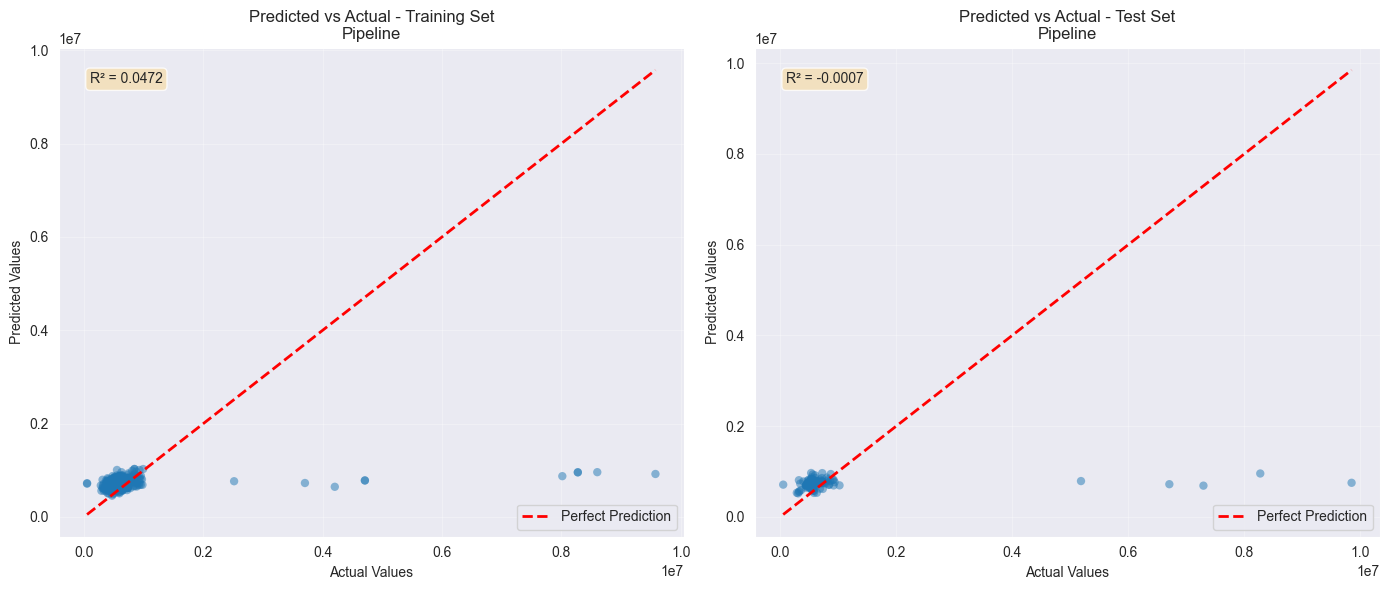

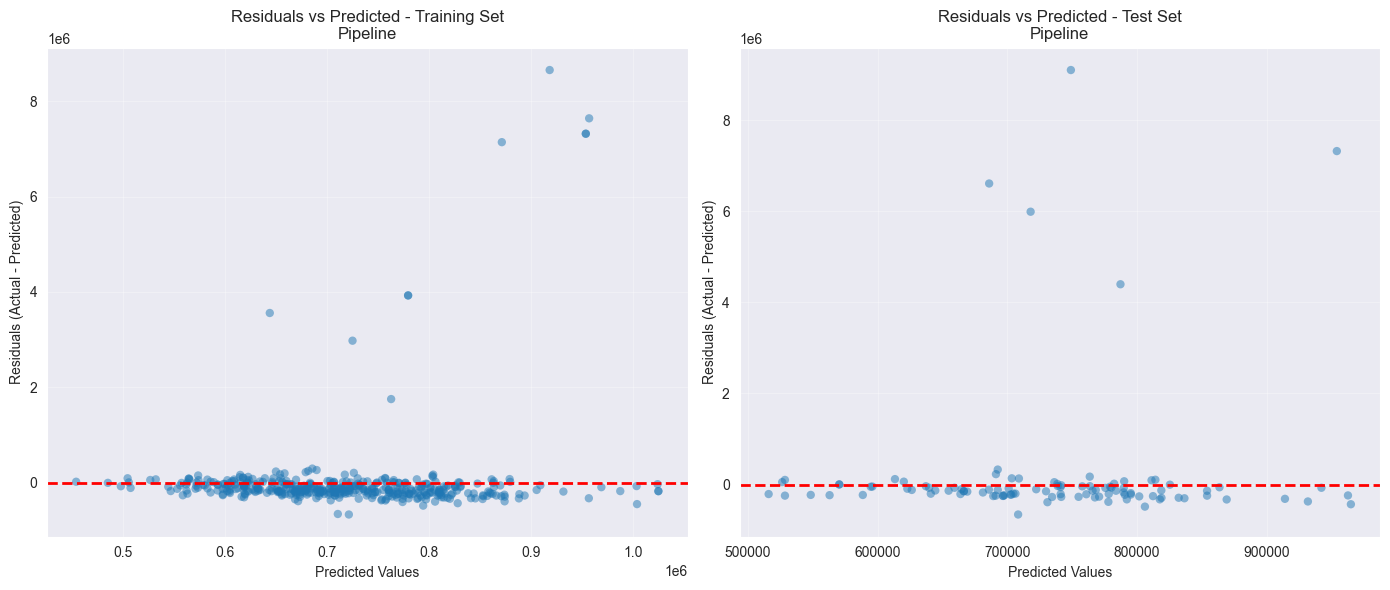

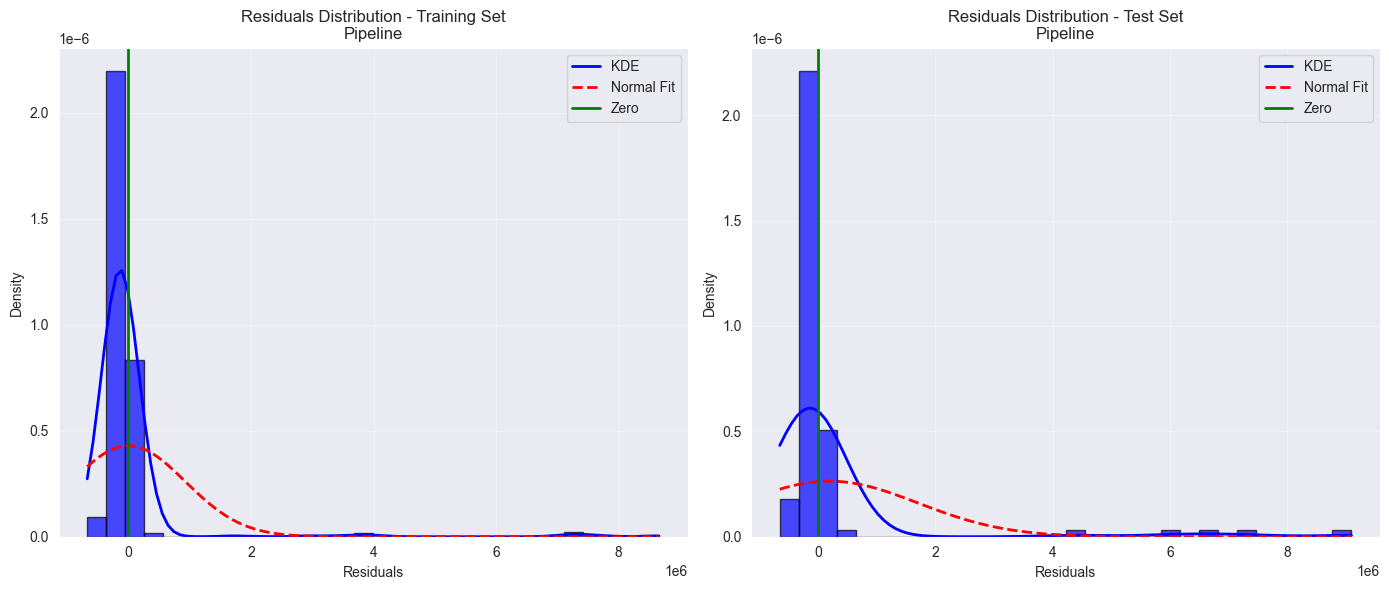

In [23]:
tuned_model = tuned_search.best_estimator_

tuned_metrics = eval_regression(
    model=tuned_model,
    X_train=X_train_scaled,
    y_train=y_train_clean,
    X_test=X_val_scaled,
    y_test=y_val_clean,
    plot_predicted_vs_actual=True,
    plot_residuals=True,
    plot_residuals_dist=True,
    n_splits=5,
    n_repeats=2,
    display=False,
)

## **STAGE 9: MODEL INTERPRETATION**

Tree ensembles expose impurity-based feature importance. Linear models expose coefficients. Both are shown on the transformed feature scale, so they describe the fitted model rather than raw dollar effects.

In [24]:
final_estimator = tuned_model[-1]

if hasattr(final_estimator, "feature_importances_"):
    importance = pd.Series(
        final_estimator.feature_importances_,
        index=X_train_scaled.columns,
    ).sort_values(ascending=False)
    importance_label = "impurity importance"
elif hasattr(final_estimator, "coef_"):
    coefficients = np.ravel(final_estimator.coef_)
    importance = pd.Series(coefficients, index=X_train_scaled.columns)
    importance = importance.reindex(importance.abs().sort_values(ascending=False).index)
    importance_label = "coefficient"
else:
    importance = None
    importance_label = "not available"

if importance is not None:
    print(f"Top features by {importance_label}:")
    display(importance.head(15).to_frame("value"))

Top features by coefficient:


,value
bedrooms,52794.130148
latitude,39438.714499
grade,39331.675765
sqft_lot,37270.348368
year_built,20385.339674
school_rating,-18370.384354
zipcode,-17757.741190
floors,16936.657887
sqft_living,15106.174403
was_renovated,-14155.256719


## **STAGE 10: FINAL TEST-SET EVALUATION**

The test set has not been used for imputation statistics, outlier limits, encoding, feature selection, scaling, or tuning. This is the unbiased estimate of generalization performance.

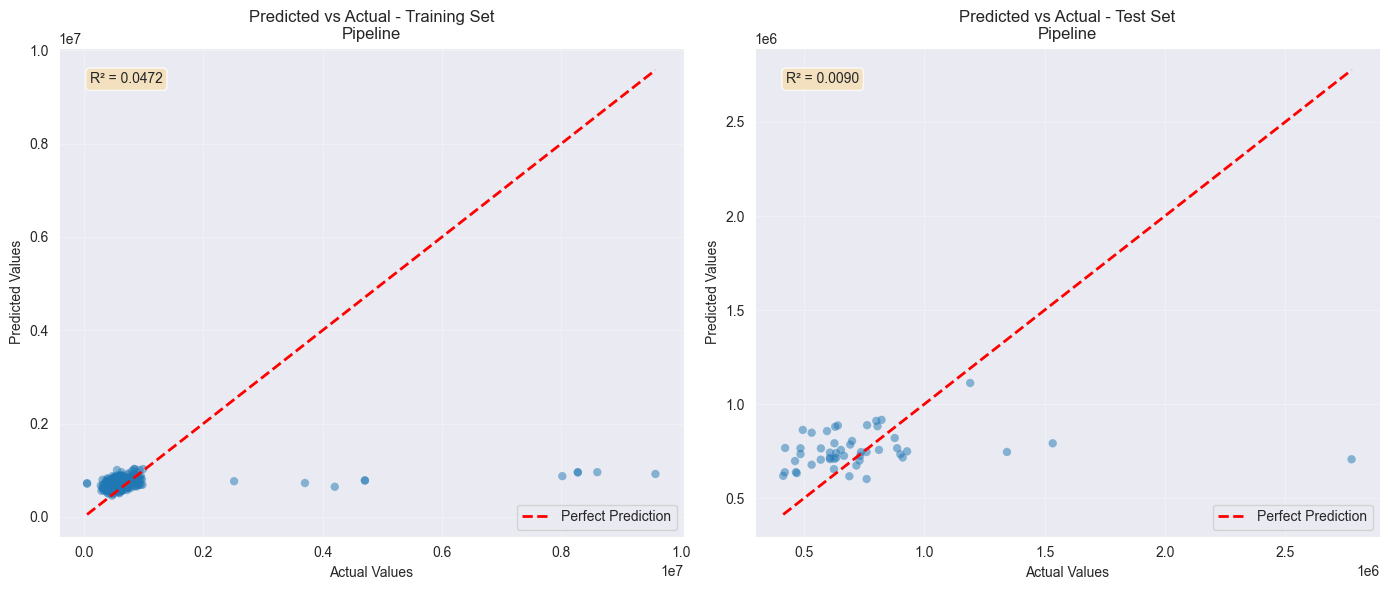

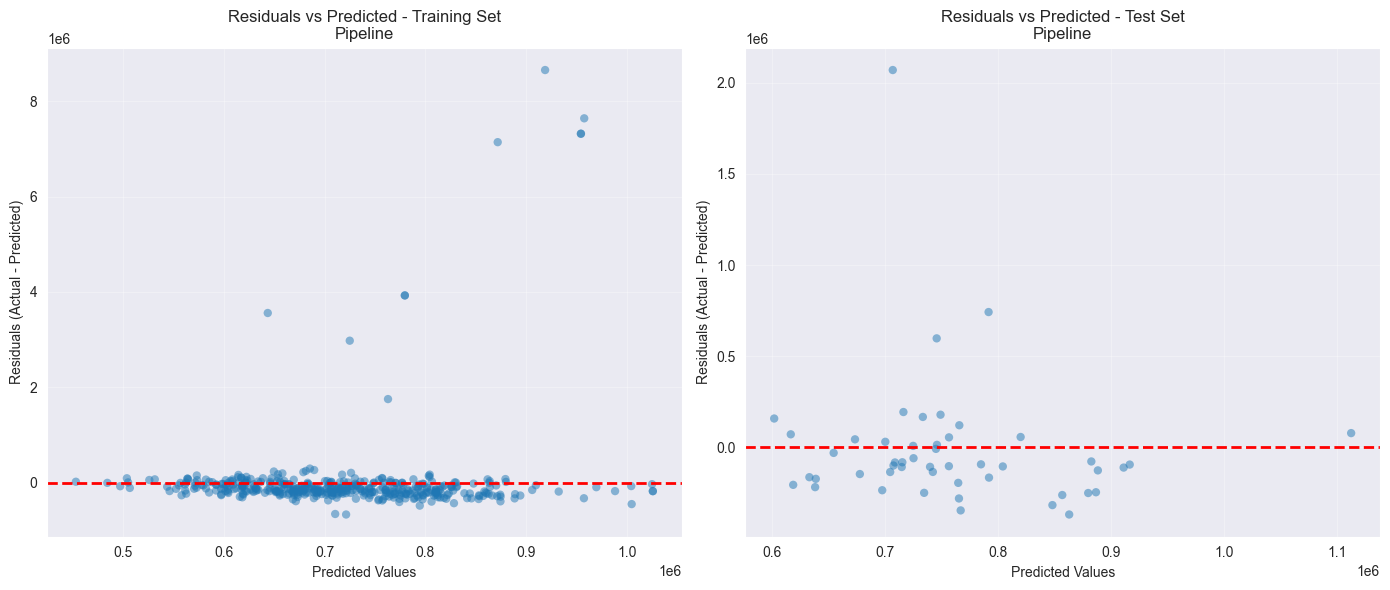

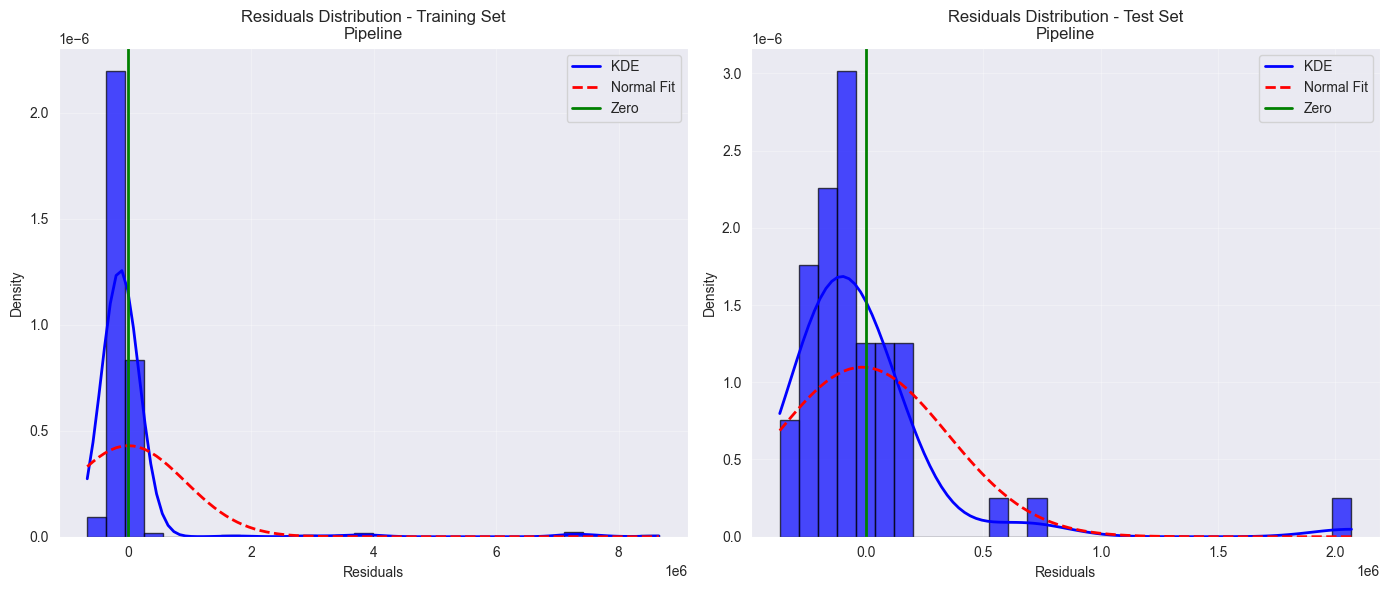

In [25]:
metrics_test = eval_regression(
    model=tuned_model,
    X_train=X_train_scaled,
    y_train=y_train_clean,
    X_test=X_test_scaled,
    y_test=y_test_raw,
    plot_predicted_vs_actual=True,
    plot_residuals=True,
    plot_residuals_dist=True,
    n_splits=5,
    n_repeats=2,
    display=False,
)

In [26]:
average_price = y_test_raw.mean()

print("FINAL TEST-SET PERFORMANCE")
print("=" * 50)
print(f"MAE:  ${metrics_test['mae']['test']:,.0f}")
print(f"RMSE: ${metrics_test['rmse']['test']:,.0f}")
print(f"MAPE: {metrics_test['mape']['test']*100:.2f}%")
print(f"R²:   {metrics_test['r2']['test']:.4f}")
print()
print(f"Average test price: ${average_price:,.0f}")
print(f"MAE as % of average price: {metrics_test['mae']['test']/average_price*100:.2f}%")
print(f"RMSE as % of average price: {metrics_test['rmse']['test']/average_price*100:.2f}%")

FINAL TEST-SET PERFORMANCE
MAE:  $203,289
RMSE: $363,750
MAPE: 26.48%
R²:   0.0090

Average test price: $741,710
MAE as % of average price: 27.41%
RMSE as % of average price: 49.04%


## **STAGE 11: BUSINESS INTERPRETATION AND NEXT STEPS**

### How to read the results
- **MAE** is the average absolute dollar error. It is the easiest metric to explain to a pricing team.
- **RMSE** is more sensitive to large misses. A much larger RMSE than MAE signals expensive outlier errors.
- **R²** describes the share of price variation explained on the test set. It is useful for comparing models, not for setting prices.
- **MAPE** can be unstable when prices are low, so treat it as a secondary diagnostic.

### Practical recommendations
1. Use the model as a **decision-support baseline**, not an automated appraisal.
2. Review the largest residual cases manually; they often reflect unique properties or data-entry issues.
3. Collect better location features (school catchment, transit, noise) if location effects remain large.
4. Re-train periodically and monitor feature drift, especially for `city`, `zipcode`, and renovation status.
5. Keep the preprocessing artifacts together with the model so inference applies the exact same imputation, encoding, and scaling steps.

### Limitations
- The dataset is synthetic and contains deliberate data-quality issues.
- The test set is small, so metric uncertainty is non-trivial.
- Outlier removal changes the target population; the model is not trained to price extreme luxury properties.
- Correlation and univariate importance do not prove causal effects.